# AIT110 - Decision Trees and Random Forests
**Nicholas Drossos** | Grand Canyon University | Topic 4

This notebook covers tree-based classification in three parts:

1. **Understanding decision trees and random forests** - how trees are grown and pruned, why random forests fix their weaknesses, and how variable importance is measured.
2. **Building the models** - a decision tree and a random forest that predict customer satisfaction, including pruning, hyperparameter tuning, and variable importance.
3. **Evaluation and interpretation** - confusion matrices, accuracy/precision/recall/F1, ROC curves and AUC, and a final recommendation.

All randomness uses a fixed seed (`42`) so every number in this notebook is reproducible.

In [1]:
# ---- Imports -------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

import os, warnings
warnings.filterwarnings("ignore")
# The grid search runs in separate worker processes, which don't inherit the line above.
# This environment variable passes the same setting on to them.
os.environ["PYTHONWARNINGS"] = "ignore"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42

# ---- Consistent plot style -----------------------------------------------
# One fixed color per model, used in every chart.
COLORS = {"Decision Tree": "#2a78d6", "Random Forest": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})

---
# Part 1: Understanding Decision Trees and Random Forests

## 1.1 How a decision tree is built

A decision tree splits the data into smaller and smaller groups by asking yes/no questions about the features, such as "Is `Delivery_Time` ≤ 8 days?". It is grown top-down with a **greedy** algorithm (recursive binary splitting):

1. Start with all training observations in one node (the root).
2. For every feature and every possible cut point, measure how "pure" the two resulting child nodes would be.
3. Pick the single split that improves purity the most, and divide the node.
4. Repeat on each child node until a stopping rule is hit (the node is pure, too small, or a maximum depth is reached).

"Greedy" means each split is the best one *right now*; the algorithm never goes back to reconsider an earlier split.

**Choosing splits: Gini index and information gain.** For a node where $\hat{p}_k$ is the share of observations in class $k$:

- **Gini index:** $G = \sum_{k} \hat{p}_k(1-\hat{p}_k)$. It is 0 when a node holds a single class and largest when classes are evenly mixed (0.5 for two classes).
- **Entropy:** $D = -\sum_{k} \hat{p}_k \log_2 \hat{p}_k$. **Information gain** is the parent's entropy minus the size-weighted entropy of the children.

The tree picks the split with the largest drop in impurity (the largest information gain, or the largest drop in Gini). In practice the two criteria almost always choose similar splits; scikit-learn uses Gini by default, and that is what this notebook uses.

**Pruning to prevent overfitting.** A tree grown until every leaf is pure memorizes the training data, noise included. Pruning trades a little training accuracy for better generalization. There are two approaches:

- **Pre-pruning (early stopping):** limit growth with rules like `max_depth` or `min_samples_leaf`.
- **Post-pruning (cost-complexity pruning):** grow a large tree, then cut it back. For a penalty $\alpha \ge 0$, find the subtree $T$ that minimizes

$$R_\alpha(T) = R(T) + \alpha\,|T|$$

where $R(T)$ is the training misclassification (impurity) and $|T|$ is the number of leaves. $\alpha = 0$ keeps the full tree; larger $\alpha$ removes more branches. The best $\alpha$ is chosen with cross-validation. Section 2.3 does exactly this.

## 1.2 Limitations of decision trees, and how random forests address them

Decision trees are easy to read, need no feature scaling, and handle non-linear effects and interactions naturally. Their weaknesses are:

- **High variance.** A small change in the training data can produce a very different tree, because an early split change ripples through every split below it.
- **Overfitting.** Deep trees fit noise; shallow trees underfit. A single tree rarely gets the balance right.
- **Coarse, step-shaped predictions** and usually **lower accuracy** than other methods.

A random forest keeps the tree as its building block but averages many of them. Averaging cancels out much of each tree's individual noise, so the forest has far lower variance and is more accurate, at the cost of the single, easy-to-draw diagram.

## 1.3 How random forests combine trees

A random forest builds $B$ trees (often hundreds) and lets them vote. Two sources of randomness make the trees different from each other:

1. **Bootstrapping (bagging).** Each tree is trained on a bootstrap sample: $n$ rows drawn *with replacement* from the $n$ training rows. On average a bootstrap sample contains about 63% of the unique rows; the other ~37% are "out-of-bag" (OOB) and can be used as a built-in validation set.
2. **Random feature selection.** At *every split*, the tree may only choose from a random subset of $m$ features (commonly $m \approx \sqrt{p}$ for classification). This stops one strong feature from dominating the top of every tree.

To classify a new observation, every tree votes and the forest takes the majority (or averages the trees' class probabilities, which is what scikit-learn does).

## 1.4 Why random forests reduce variance

If $B$ predictions each have variance $\sigma^2$ and pairwise correlation $\rho$, the variance of their average is

$$\rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

Adding more trees (larger $B$) shrinks the second term toward zero. Bagging alone leaves the first term, $\rho\sigma^2$, because trees grown on similar data are highly correlated. Random feature selection lowers $\rho$ by forcing the trees to differ, which shrinks the first term too.

This matters because a model's expected error is bias² + variance + irreducible noise. A deep tree has low bias but high variance. The forest keeps that low bias and removes most of the variance, so its test accuracy is higher and much more stable from sample to sample.

## 1.5 Variable importance in random forests

Because a forest has hundreds of trees, it can't be read like a single diagram. Instead, it summarizes how much each feature contributed:

- **Mean decrease in impurity (MDI, Gini importance):** every time a feature is used to split, record how much it lowered the Gini index (weighted by the number of samples reaching that node). Sum over all trees and normalize so the values add to 1.
- **Permutation importance (mean decrease in accuracy):** shuffle one feature's values in held-out data, which breaks its link to the target, and measure how much accuracy drops. A big drop means the model depends on that feature.

MDI is fast but can favor continuous, high-cardinality features (like `Price`) because they offer more possible cut points. Permutation importance on test data doesn't have that bias, so it's a good check. Features near the top of both rankings are the ones driving the model's decisions; features near zero could be dropped with little loss. Importance shows *how much* a feature matters, not the *direction* of its effect, so it should be read alongside the tree splits.

---
# Part 2: Building Decision Trees and Random Forests

## 2.1 Load and explore the data

The dataset (`retail_customer_satisfaction_3000.csv`) has 3,000 customers with `Satisfaction` (Yes/No) as the target and five predictors: `Product_Quality` (1-10), `Delivery_Time` (days, 1-14), `Customer_Service` (1-10), `Price`, and `Customer_Loyalty` (10-100). There are no missing values.

The classes are **imbalanced: about 81% of customers are satisfied**. That matters for evaluation, because a "model" that always answers "Yes" would already be about 81% accurate. I print that majority-class baseline below so every accuracy in this notebook can be compared to it, and Part 3 looks beyond accuracy at how well each model finds the *unsatisfied* customers.

In [2]:
# ---- 2.1 Load the data ----------------------------------------------------
df = pd.read_csv("retail_customer_satisfaction_3000.csv")
features = ["Product_Quality", "Delivery_Time", "Customer_Service", "Price", "Customer_Loyalty"]

print("Shape:", df.shape, "| Missing values:", int(df.isna().sum().sum()))
print("\nClass balance:")
print(df["Satisfaction"].value_counts(normalize=True).round(3))
df.describe().T

Shape: (3000, 6) | Missing values: 0

Class balance:
Satisfaction
Yes   0.809
No    0.191
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Product_Quality,"3,000.000",5.459,2.881,1.000,3.000,5.000,8.000,10.000
Delivery_Time,"3,000.000",7.507,4.014,1.000,4.000,8.000,11.000,14.000
Customer_Service,"3,000.000",5.549,2.878,1.000,3.000,6.000,8.000,10.000
Price,"3,000.000",257.181,140.957,10.660,139.067,260.655,380.425,499.880
Customer_Loyalty,"3,000.000",54.983,18.981,10.000,41.000,55.000,69.000,100.000


In [3]:
# ---- Train/test split -----------------------------------------------------
# Encode the target as 1 = satisfied, 0 = not satisfied.
X = df[features]
y = (df["Satisfaction"] == "Yes").astype(int)

# 75/25 split, stratified so both sets keep the same Yes/No balance.
# Trees don't need feature scaling, so the raw values are used directly.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

# Baseline: always predicting the majority class ("Satisfied")
print(f"Majority-class baseline accuracy (test): {y_test.mean():.3f}")

# The same 5-fold splitter is reused for every cross-validation step.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: 2250 rows | Test: 750 rows
Majority-class baseline accuracy (test): 0.808


## 2.2 Decision tree model (Part 2, question 1)

First, a tree with no limits on its growth, using all five features.

In [4]:
# ---- 2.2 Full (unpruned) decision tree -------------------------------------
full_tree = DecisionTreeClassifier(criterion="gini", random_state=SEED).fit(X_train, y_train)

print(f"Depth: {full_tree.get_depth()} | Leaves: {full_tree.get_n_leaves()}")
print(f"Training accuracy: {accuracy_score(y_train, full_tree.predict(X_train)):.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, full_tree.predict(X_test)):.3f}")

Depth: 19 | Leaves: 230
Training accuracy: 1.000
Test accuracy:     0.880


The unpruned tree grew to depth 19 with 230 leaves and got **100% of the training data right but 88.0% of the test data**. That gap is overfitting: with 230 leaves for 2,250 customers, many leaves hold only a few people, so the tree has memorized noise. This is the tree's high-variance problem from Section 1.2.

## 2.3 Pruning the tree (Part 2, question 3)

I use **cost-complexity pruning**. scikit-learn computes every $\alpha$ value at which a branch would be removed from the full tree. For each candidate $\alpha$, 5-fold cross-validation on the training set estimates how well that pruned tree generalizes. The test set is not used here.

Best ccp_alpha: 0.00300
CV accuracy at best alpha: 0.906 (+/- 0.002)
Leaves at best alpha: 7 (full tree: 230)


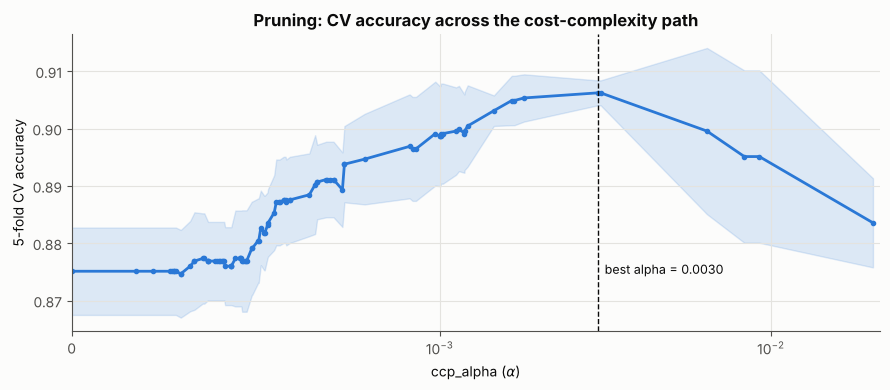

In [5]:
# ---- 2.3 Cost-complexity pruning path ---------------------------------------
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]          # the last alpha prunes down to the root alone

cv_mean, cv_std, n_leaves = [], [], []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=SEED)
    scores = cross_val_score(t, X_train, y_train, cv=cv, scoring="accuracy")
    cv_mean.append(scores.mean()); cv_std.append(scores.std())
    n_leaves.append(t.fit(X_train, y_train).get_n_leaves())
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)

best_i = int(np.argmax(cv_mean))
best_alpha = alphas[best_i]
print(f"Best ccp_alpha: {best_alpha:.5f}")
print(f"CV accuracy at best alpha: {cv_mean[best_i]:.3f} (+/- {cv_std[best_i]:.3f})")
print(f"Leaves at best alpha: {n_leaves[best_i]} (full tree: {full_tree.get_n_leaves()})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(alphas, cv_mean, color=COLORS["Decision Tree"], marker="o", markersize=3)
ax.fill_between(alphas, cv_mean - cv_std, cv_mean + cv_std, color=COLORS["Decision Tree"], alpha=0.15)
ax.axvline(best_alpha, color=INK, linestyle="--", linewidth=1)
ax.text(best_alpha, ax.get_ylim()[0] + 0.01, f"  best alpha = {best_alpha:.4f}", fontsize=9)
ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(left=0)
ax.set_xlabel(r"ccp_alpha ($\alpha$)"); ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Pruning: CV accuracy across the cost-complexity path")
plt.tight_layout(); plt.show()

In [6]:
# ---- Fit the pruned tree with the chosen alpha ------------------------------
tree = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=SEED).fit(X_train, y_train)
print(f"Pruned tree depth: {tree.get_depth()} | Leaves: {tree.get_n_leaves()}")
print(f"Training accuracy: {accuracy_score(y_train, tree.predict(X_train)):.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, tree.predict(X_test)):.3f}")

Pruned tree depth: 4 | Leaves: 7
Training accuracy: 0.913
Test accuracy:     0.936


**Pruning criterion.** I chose the $\alpha$ with the highest 5-fold cross-validated accuracy, $\alpha = 0.0030$. I used cross-validation instead of training accuracy because training accuracy always prefers the full tree, and instead of the test set because the test set has to stay untouched for the final comparison in Part 3.

The plot shows the usual U-shape. Small $\alpha$ (big trees) overfit and score about 0.875; CV accuracy climbs as branches are removed, peaks at 0.906, then falls when $\alpha$ gets large enough to cut useful splits. Pruning cut the tree from 230 leaves to **7 leaves (depth 4)**. Training accuracy fell from 1.000 to 0.913, but **test accuracy rose from 0.880 to 0.936**. The small tree generalizes much better than the big one.

## 2.4 Visualizing the tree and the first three splits (Part 2, question 2)

The pruned tree is small enough to show in full. Blue nodes lean "Satisfied", orange nodes lean "Not satisfied", and darker means purer.

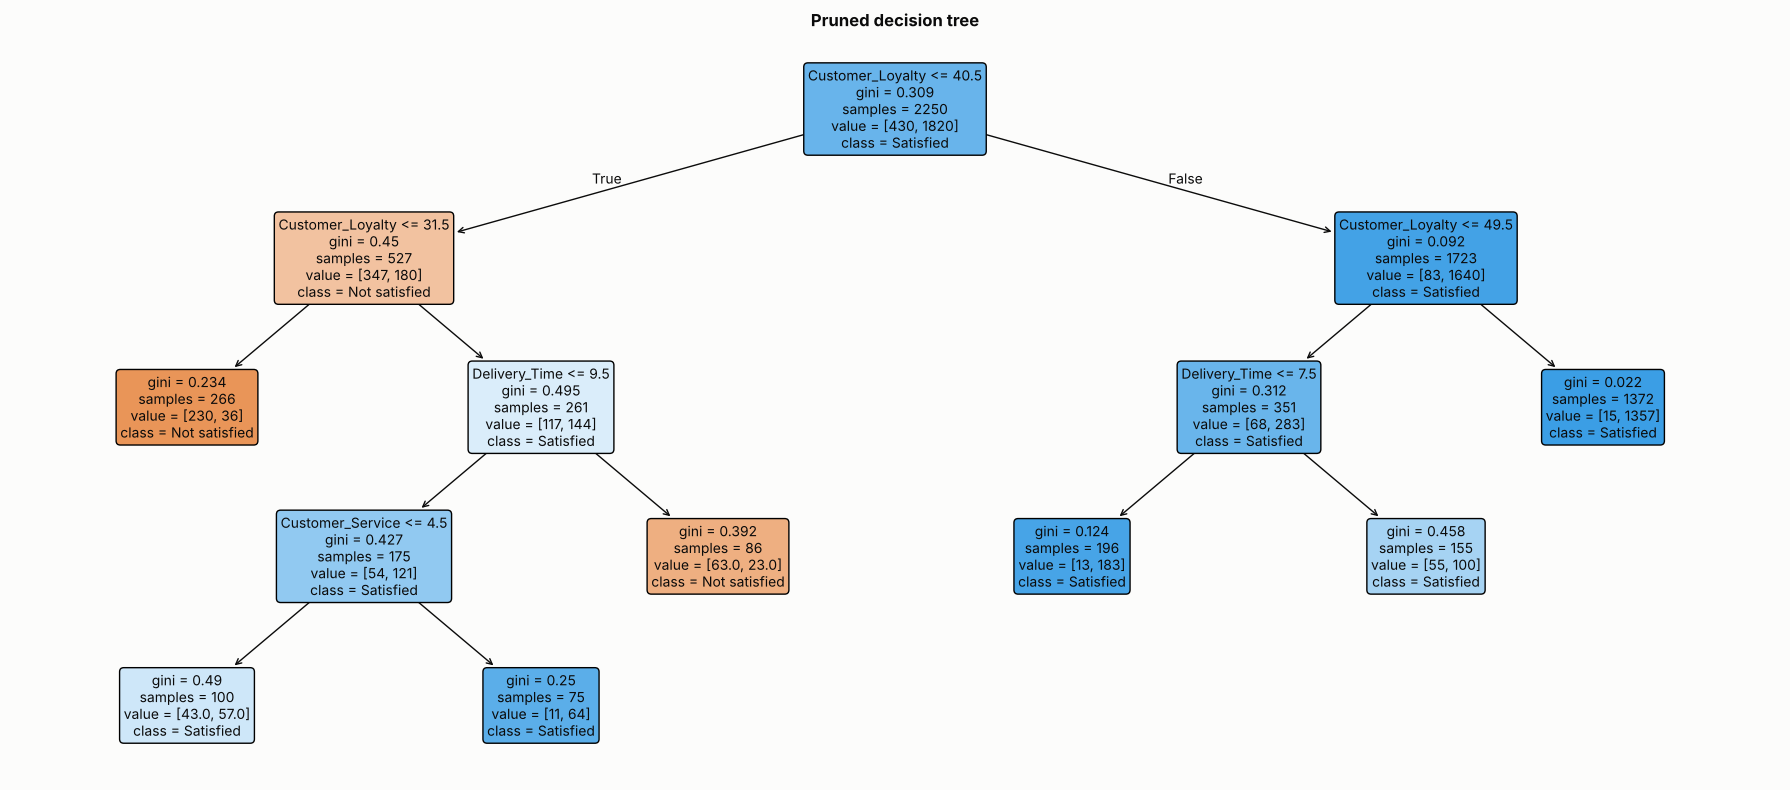

In [7]:
# ---- 2.4 Plot the top of the pruned tree ------------------------------------
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=features, class_names=["Not satisfied", "Satisfied"],
          filled=True, rounded=True, impurity=True, proportion=False,
          fontsize=10, ax=ax)
ax.set_title("Pruned decision tree")
plt.tight_layout(); plt.show()

In [8]:
# ---- Print the first three splits (root, then its left and right children) --
t = tree.tree_
def describe(node):
    return (f"{features[t.feature[node]]} <= {t.threshold[node]:.2f} "
            f"(n = {t.n_node_samples[node]}, Gini = {t.impurity[node]:.3f})")

root, left, right = 0, t.children_left[0], t.children_right[0]
print("Split 1 (root):          ", describe(root))
print("Split 2 (if split 1 yes):", describe(left)  if t.feature[left]  >= 0 else "leaf")
print("Split 3 (if split 1 no): ", describe(right) if t.feature[right] >= 0 else "leaf")

Split 1 (root):           Customer_Loyalty <= 40.50 (n = 2250, Gini = 0.309)
Split 2 (if split 1 yes): Customer_Loyalty <= 31.50 (n = 527, Gini = 0.450)
Split 3 (if split 1 no):  Customer_Loyalty <= 49.50 (n = 1723, Gini = 0.092)


**Interpreting the first three splits.** All splits use the Gini index; each one is the cut that lowered Gini the most at that node.

1. **Root: `Customer_Loyalty` ≤ 40.5.** Loyalty is the single best separator. Customers with loyalty 41 or higher are 95% satisfied (1,640 of 1,723). Those at 40 or below are mostly unhappy (347 of 527). The children's Gini of 0.092 shows how pure the high-loyalty side already is.
2. **Low-loyalty branch: `Customer_Loyalty` ≤ 31.5.** The model splits on loyalty again. Below 32, 86% of customers are unhappy (230 of 266), the clearest "not satisfied" group in the tree. Between 32 and 40 it's close to a toss-up, and the tree goes on to use delivery time and customer service to settle it.
3. **High-loyalty branch: `Customer_Loyalty` ≤ 49.5.** Above 49, 99% of customers are satisfied (1,357 of 1,372), and the tree stops. Between 41 and 49, it checks delivery time: 7 days or less keeps 93% satisfied, but slower deliveries drop that to 65%.

So the model **prioritizes `Customer_Loyalty` for all three of the first splits**, then uses `Delivery_Time` and `Customer_Service` to sort the borderline customers. `Product_Quality` and `Price` don't appear in the pruned tree. That doesn't mean product quality is irrelevant. Loyalty is strongly correlated with product quality (r = 0.78) and customer service (r = 0.63), so a loyalty split already captures most of their information, and the greedy algorithm takes the single most useful feature at each step.

## 2.5 Random forest model (Part 2, question 4)

A baseline forest with scikit-learn's defaults: 100 trees, no depth limit, $\sqrt{p}$ features tried at each split.

In [9]:
# ---- 2.5 Baseline random forest ---------------------------------------------
rf_base = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=SEED, n_jobs=-1)
rf_base.fit(X_train, y_train)
print(f"Out-of-bag accuracy: {rf_base.oob_score_:.3f}")
print(f"Test accuracy:       {accuracy_score(y_test, rf_base.predict(X_test)):.3f}")

Out-of-bag accuracy: 0.909
Test accuracy:       0.916


## 2.6 Tuning the random forest (Part 2, question 5)

I tune three hyperparameters with a grid search and 5-fold cross-validation on the training set:

- `n_estimators`: the number of trees
- `max_depth`: how deep each tree can grow
- `max_features`: how many features each split can choose from

The combination with the highest mean CV accuracy is selected and then refit on the full training set.

In [10]:
# ---- 2.6 Grid search over the main hyperparameters --------------------------
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [3, 5, 7, 10, None],
    "max_features": ["sqrt", 3, None],      # None = all 5 features (plain bagging)
}
# The grid search runs folds in parallel, so each forest runs on a single core
# (nesting parallel jobs inside parallel jobs causes joblib warnings).
grid = GridSearchCV(RandomForestClassifier(random_state=SEED),
                    param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")
rf = grid.best_estimator_
print(f"Test accuracy of tuned forest: {accuracy_score(y_test, rf.predict(X_test)):.3f}")

Best hyperparameters: {'max_depth': 5, 'max_features': 3, 'n_estimators': 100}
Best CV accuracy: 0.919
Test accuracy of tuned forest: 0.936


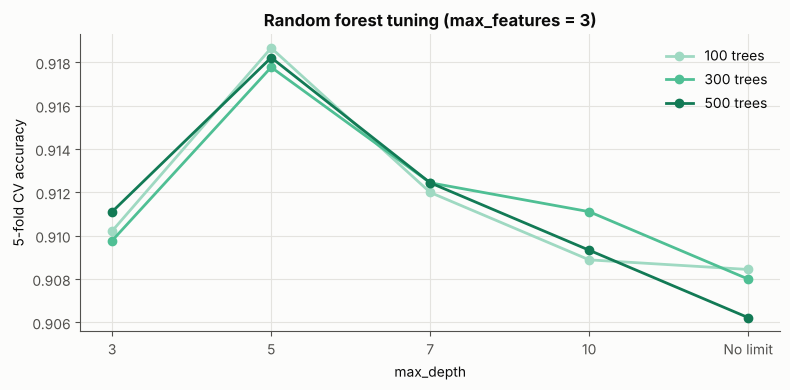

In [11]:
# ---- How CV accuracy changes with depth and number of trees -------------------
res = pd.DataFrame(grid.cv_results_)
best_mf = grid.best_params_["max_features"]
res = res[[mf == best_mf for mf in res["params"].map(lambda p: p["max_features"])]]
res["depth"] = res["params"].map(lambda p: "No limit" if p["max_depth"] is None else str(p["max_depth"]))
order = ["3", "5", "7", "10", "No limit"]

fig, ax = plt.subplots(figsize=(8, 4))
shades = {100: "#9fd9c2", 300: "#4fbf94", 500: "#127a55"}
for n_est, grp in res.groupby("param_n_estimators"):
    grp = grp.set_index("depth").loc[order]
    ax.plot(order, grp["mean_test_score"], marker="o", color=shades[n_est], label=f"{n_est} trees")
ax.set_xlabel("max_depth"); ax.set_ylabel("5-fold CV accuracy")
ax.set_title(f"Random forest tuning (max_features = {grid.best_params_['max_features']})")
ax.legend(); plt.tight_layout(); plt.show()

**Optimal hyperparameters:** `n_estimators = 100`, `max_depth = 5`, `max_features = 3`, with a CV accuracy of 0.919. I chose them by grid search: all 45 combinations were scored with the same 5-fold CV on the training set, and the highest mean accuracy won.

The plot shows that **depth is the hyperparameter that matters**. Accuracy peaks at depth 5 and falls steadily as trees get deeper, because deep trees fit noise even inside a forest. The number of trees barely matters: 100, 300, and 500 trees are within about 0.2 percentage points at every depth, so 100 is enough and the cheapest. Trying 3 of the 5 features at each split did slightly better than $\sqrt{5} \approx 2$ or all 5.

## 2.7 Comparing the two models (Part 2, question 6)

In [12]:
# ---- 2.7 Accuracy comparison -------------------------------------------------
comparison = pd.DataFrame({
    "Model": ["Decision Tree (pruned)", "Random Forest (tuned)"],
    "CV accuracy (train)": [cv_mean[best_i], grid.best_score_],
    "Test accuracy": [accuracy_score(y_test, tree.predict(X_test)),
                      accuracy_score(y_test, rf.predict(X_test))],
})
comparison

,Model,CV accuracy (train),Test accuracy
0,Decision Tree (pruned),0.906,0.936
1,Random Forest (tuned),0.919,0.936


**On test accuracy the two models tie at 0.936.** Cross-validation gives a small edge to the forest (0.919 vs. 0.906), and both are well above the 0.808 baseline.

The forest didn't win clearly here because the problem suits a simple tree. Most of the signal comes from one feature (loyalty) with sharp cutoffs, which a tree captures directly. The variance reduction from averaging (Section 1.4) mostly helps when a single tree is unstable, and pruning had already made this tree stable: its CV standard deviation was only ±0.002. The forest still has the edge in CV and, as Part 3 shows, in AUC and in catching unsatisfied customers, but the gap is small.

## 2.8 Variable importance (Part 2, question 7)

Both importance measures from Section 1.5, computed from the tuned forest. Permutation importance is calculated on the **test set** and repeated 30 times; the error bars show its spread.

,Gini importance (MDI),Permutation importance (accuracy drop),Permutation std
Customer_Loyalty,0.576,0.180,0.011
Customer_Service,0.177,0.021,0.005
Product_Quality,0.119,0.007,0.003
Delivery_Time,0.100,0.029,0.006
Price,0.028,-0.002,0.002


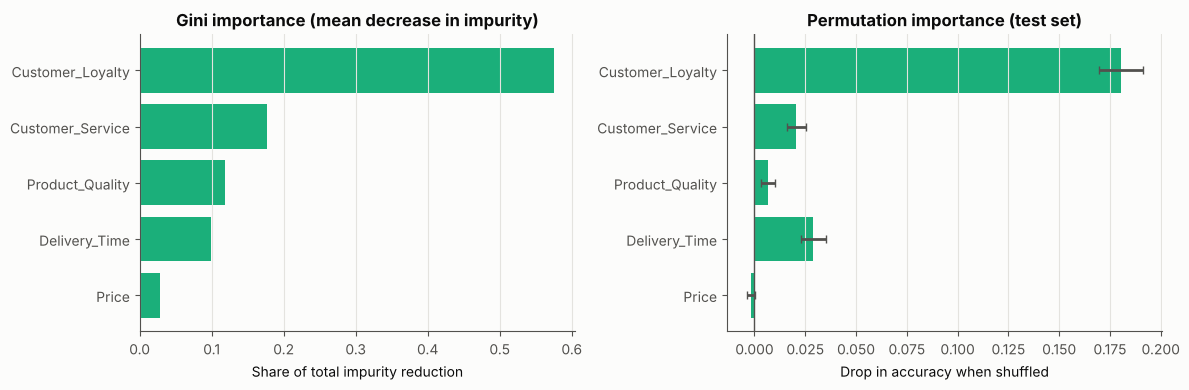

In [13]:
# ---- 2.8 Gini (MDI) and permutation importance -------------------------------
mdi = pd.Series(rf.feature_importances_, index=features)
perm = permutation_importance(rf, X_test, y_test, n_repeats=30, random_state=SEED, scoring="accuracy")
perm_mean = pd.Series(perm.importances_mean, index=features)
perm_std = pd.Series(perm.importances_std, index=features)

importance = pd.DataFrame({"Gini importance (MDI)": mdi,
                           "Permutation importance (accuracy drop)": perm_mean,
                           "Permutation std": perm_std}).sort_values("Gini importance (MDI)", ascending=False)
display(importance)

order = importance.index[::-1]   # largest at the top of the bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(order, mdi[order], color=COLORS["Random Forest"])
axes[0].set_title("Gini importance (mean decrease in impurity)")
axes[0].set_xlabel("Share of total impurity reduction")
axes[1].barh(order, perm_mean[order], xerr=perm_std[order], color=COLORS["Random Forest"],
             error_kw={"ecolor": MUTED, "capsize": 3})
axes[1].axvline(0, color=MUTED, linewidth=1)
axes[1].set_title("Permutation importance (test set)")
axes[1].set_xlabel("Drop in accuracy when shuffled")
for ax in axes: ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Interpretation (Part 2, question 8)

**`Customer_Loyalty` dominates both measures**: 58% of the total Gini reduction, and shuffling it costs the forest 18 points of test accuracy. No other feature costs more than 3 points.

The two measures disagree on the rest, and the reason is correlation. Gini importance ranks `Customer_Service` (0.18) and `Product_Quality` (0.12) second and third, because the trees do use them for splits. Permutation importance gives them only 2.1 and 0.7 points, because when one of them is shuffled, loyalty, which is correlated with both, still carries most of the same information. `Delivery_Time` is the opposite: it is unrelated to loyalty (r = 0.03), so it adds information nothing else has, and it ranks second on permutation importance (2.9 points). **`Price` is unimportant** in both measures; its permutation importance is slightly negative, which means shuffling it made no difference. Customers are equally satisfied (about 80%) at every price level.

**What this means for the business:** loyalty is the best single *signal* of satisfaction, but it is mostly an *outcome* of a good product and good service, so it isn't something the company can change directly. The levers are product quality and customer service, which build loyalty, plus delivery time, which affects satisfaction on its own. Price is not a lever.

---
# Part 3: Model Evaluation and Interpretation

## 3.1 Confusion matrices (Part 3, question 1)

Both models are evaluated on the 750-customer test set, which neither model saw during training or tuning.

Decision Tree  TN=108  FP= 36  FN= 12  TP=594
Random Forest  TN=113  FP= 31  FN= 17  TP=589


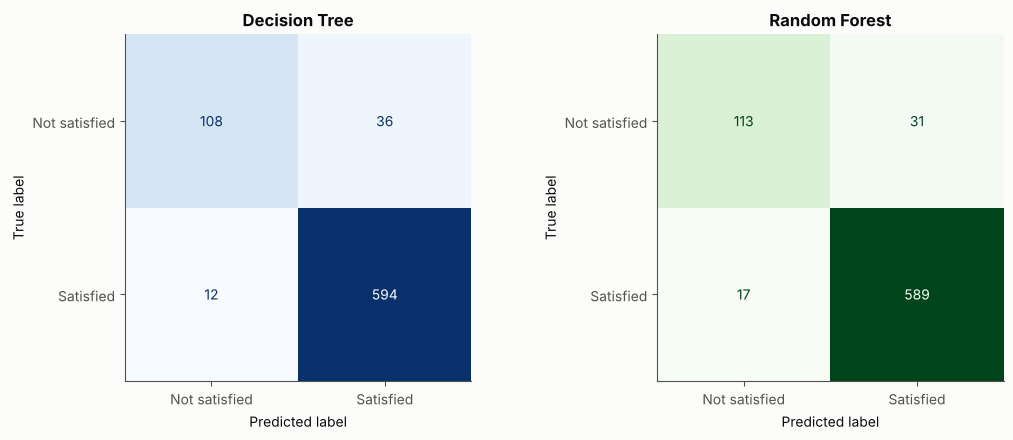

In [14]:
# ---- 3.1 Confusion matrices -----------------------------------------------------
models = {"Decision Tree": tree, "Random Forest": rf}
labels = ["Not satisfied", "Satisfied"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues" if name == "Decision Tree" else "Greens", colorbar=False)
    ax.set_title(name); ax.grid(False)
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:14s} TN={tn:3d}  FP={fp:3d}  FN={fn:3d}  TP={tp:3d}")
plt.tight_layout(); plt.show()

## 3.2 Accuracy, precision, recall, and F1 (Part 3, question 2)

"Positive" here means **satisfied**.

- **Accuracy:** share of all predictions that are correct.
- **Precision:** of the customers predicted satisfied, the share who really were.
- **Recall:** of the customers who really were satisfied, the share the model found.
- **F1:** the harmonic mean of precision and recall.

In [15]:
# ---- 3.2 Metric table ---------------------------------------------------------------
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
metrics = pd.DataFrame(rows).set_index("Model")
metrics

,Accuracy,Precision,Recall,F1
Model,,,,
Decision Tree,0.936,0.943,0.980,0.961
Random Forest,0.936,0.950,0.972,0.961


Both models reach 0.936 accuracy and 0.961 F1, so the summary numbers are tied. The confusion matrices show where they differ:

- The **random forest catches more unsatisfied customers**: 113 of 144 (78.5%) vs. 108 (75.0%) for the tree, so it makes fewer false positives (31 vs. 36) and has higher precision (0.950 vs. 0.943).
- The **tree finds slightly more satisfied customers** (recall 0.980 vs. 0.972), but with 81% of customers satisfied, that is the easy part.

Because the classes are imbalanced, recall and precision on "satisfied" both look high for any reasonable model. The more telling number is how many of the 144 unsatisfied customers each model finds. For the business, missing an unhappy customer (a false positive) is the costly mistake, because that customer never gets a follow-up. On that measure the forest is slightly better.

## 3.3 ROC curves and AUC (Part 3, questions 3 and 4)

The ROC curve plots the true positive rate against the false positive rate as the classification threshold moves from 1 to 0. A model that guesses at random follows the diagonal.

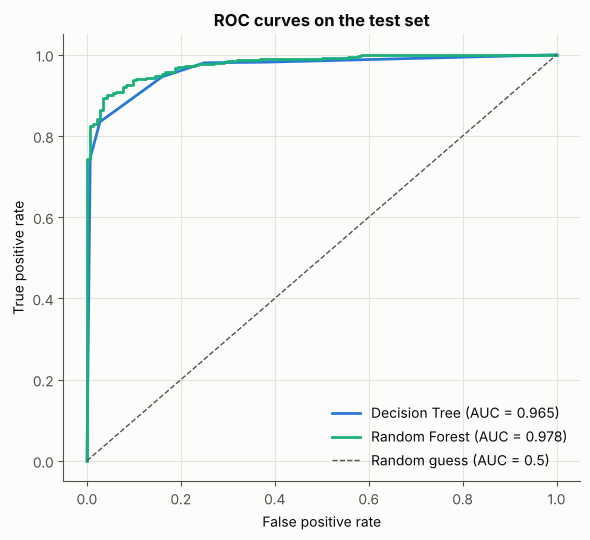

Decision Tree  AUC = 0.965
Random Forest  AUC = 0.978


In [16]:
# ---- 3.3 ROC curves and AUC -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5.5))
auc = {}
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc[name] = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC = {auc[name]:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

for name, v in auc.items():
    print(f"{name:14s} AUC = {v:.3f}")

**Random forest AUC = 0.978; decision tree AUC = 0.965.** The AUC is the probability that the model gives a randomly chosen satisfied customer a higher score than a randomly chosen unsatisfied one. 0.5 is guessing and 1.0 is perfect separation. Both models separate the two groups very well, and AUC is a better summary than accuracy here because it is not affected by the 81/19 class imbalance.

The forest has the higher AUC even though accuracy is tied. Accuracy only checks one threshold (0.5); AUC checks all of them. The pruned tree has 7 leaves, so it can only output 7 different probabilities, and its curve is a few straight segments. The forest averages 100 trees and gives every customer a fine-grained probability, so it **ranks** customers better, especially at the low false positive rates on the left side of the plot. That ranking is what the company would use to decide which customers to contact first.

## 3.4 Final model selection (Part 3, question 5)

The two models are close, so this is a judgment call:

| | Decision Tree | Random Forest |
|---|---|---|
| Test accuracy | 0.936 | 0.936 |
| CV accuracy | 0.906 | 0.919 |
| F1 | 0.961 | 0.961 |
| Unsatisfied customers caught | 108 of 144 | 113 of 144 |
| AUC | 0.965 | 0.978 |

**I recommend the random forest for scoring customers.** It is better or tied on every measure: higher CV accuracy, higher AUC, and it finds more of the unhappy customers, which is the group the company actually needs to act on. Its averaging also makes it less sensitive to which customers happen to be in the training data.

The pruned decision tree is a strong second choice and is better for **explaining** the results. Seven leaves with clear cutoffs ("loyalty below 32: 86% unhappy") are easy to put in front of managers. A good setup is to use the forest to score and rank customers and the tree to communicate why.

## 3.5 Business implications (Part 3, question 6)

The importance results and the tree's splits point to where the company should spend its attention:

1. **Use loyalty as the early-warning signal.** It is the strongest predictor by far. Customers with loyalty below about 32 are unhappy 86% of the time, and customers above about 50 are almost always satisfied. Low-loyalty customers (roughly a quarter of the base) should be flagged for proactive outreach.
2. **Raise loyalty through product quality and customer service.** Loyalty can't be changed directly; it is strongly tied to quality (r = 0.78) and service (r = 0.63). On their own, satisfaction rises from about 53-56% for customers rating quality or service 1-3 to about 99% for those rating them 8-10. These are the real levers.
3. **Fix slow deliveries for borderline customers.** Delivery time adds information loyalty doesn't. For customers in the middle loyalty range, delivery over about 7-9 days is what tips them into being unhappy. Faster shipping, or proactive updates when orders run late, should be targeted at this group.
4. **Don't compete on price.** Satisfaction is about 80% at every price level, from under 100 to nearly 500. Discounts would cost margin without improving satisfaction.

In practice, the forest can score every customer, and the ones it ranks least likely to be satisfied can get a service check-in before they leave. These are associations, not proven causes, so changes like a faster delivery option should be tested on a group of customers before rolling them out everywhere.

---
## References

- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer. (Ch. 8: Tree-Based Methods)
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.